# The Hatch C2 · Housing · Regresión

Preparación → train/test → entrenamiento y validación cruzada → evaluación → interpretación.
Este notebook se ejecuta de forma independiente. Seleccioná el kernel del entorno
del proyecto y ejecutá **Run All**. Ver `../README.md` para instalar dependencias.

| Datos | Fuente |
| --- | --- |
| `data/housing.csv` | [California Housing Prices · Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices), aportado al proyecto |

El CSV se lee localmente desde `data/`, sin descargas.

Antecedente: `C1_The_hatch/notebooks/01_viviendas.ipynb`.


### 1. Configuración

Preparamos las variables numéricas con mediana y escalado; las categóricas con
moda y one-hot. Cada fold ajusta su propio Pipeline: ni la imputación ni el escalado
aprenden del test. Usamos 80/20 y semilla 42.


In [ ]:
# Bibliotecas para configuración del entorno.
import sys
from pathlib import Path
import warnings

# Herramientas para el análisis de datos y los gráficos.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Componentes de preparación, entrenamiento y evaluación de modelos.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Detectar problemas de convergencia y localizar los CSV desde la raíz o notebooks/.
warnings.filterwarnings('error', category=ConvergenceWarning)
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Ejecutá el notebook desde la raíz del proyecto o notebooks/.')
print('Python:', sys.executable)


def pipeline(X, modelo):
    # Identificar las variables numéricas para aplicar su preparación.
    numericas = X.select_dtypes('number').columns

    # Imputar y escalar numéricas; imputar y codificar categóricas.
    preparar = ColumnTransformer(
        [
            (
                'num',
                make_pipeline(
                    SimpleImputer(strategy='median'),
                    StandardScaler(),
                ),
                numericas,
            ),
            (
                'cat',
                make_pipeline(
                    SimpleImputer(strategy='most_frequent'),
                    OneHotEncoder(
                        drop='first',
                        handle_unknown='ignore',
                        sparse_output=False,
                    ),
                ),
                X.columns.difference(numericas),
            ),
        ]
    )

    # Integrar la preparación y el modelo en un único Pipeline.
    return Pipeline([('preparar', preparar), ('modelo', modelo)])


### 2. Housing · Recordatorio del EDA y preparación

El EDA anterior detectó dormitorios faltantes, asociación ingreso/precio y un tope
en el valor objetivo. Verificamos estos puntos y conservamos todas las filas,
incluidos extremos y topes. No reutilizamos el subconjunto curado ni la imputación
global del EDA: cambiarían la población o filtrarían información a la evaluación.

Una fila es una **zona censal**, no una casa. Predecimos `median_house_value` en
**USD de 1990**. `median_income` está escalado. Usamos las nueve columnas predictoras
originales para mantener el código breve; los ratios explorados en C1 son opcionales.


In [ ]:
# Cargar los datos y revisar ejemplos, faltantes y duplicados.
housing = pd.read_csv(DATA_DIR / 'housing.csv')
display(housing.head(3))
display(housing.isna().sum().rename('faltantes').to_frame())
print('Dimensiones:', housing.shape, '| Duplicados:', housing.duplicated().sum())

# Revisar el valor máximo y cuántas zonas alcanzan ese tope.
print(
    'Máximo y zonas en él:',
    housing.median_house_value.max(),
    housing.median_house_value.eq(housing.median_house_value.max()).sum(),
)

# Comprobar el objetivo y separar las variables predictoras del precio.
assert housing.median_house_value.notna().all()
Xh, yh = housing.drop(columns='median_house_value'), housing.median_house_value

# Reservar el 20 % para test con una división reproducible.
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh,
    yh,
    test_size=.2,
    random_state=42,
)
print('Train/test:', len(Xh_train), len(Xh_test))

# Consultar la relación entre ingreso y precio solo en entrenamiento.
print(
    'Correlación ingreso/precio en train:',
    Xh_train.median_income.corr(yh_train).round(3),
)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


,faltantes
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Dimensiones: (20640, 10) | Duplicados: 0
Máximo y zonas en él: 500001.0 965
Train/test: 16512 4128
Correlación ingreso/precio en train: 0.691


### Entrenamiento: media, lineal, Ridge y Lasso

El baseline predice la media. Ridge penaliza coeficientes con L2; Lasso usa L1 y
puede llevarlos a cero. Elegimos `alpha` y modelo por **menor RMSE de CV en train**,
con cinco folds comunes. La regularización no garantiza mejorar.

RMSE = raíz del promedio de errores cuadrados; penaliza más los errores grandes.
MAE = promedio de errores absolutos. Ambos están en USD de 1990; R² no tiene unidad
y puede ser negativo. El test queda reservado hasta fijar el ganador por CV.


In [ ]:
# Definir los modelos y los valores de regularización que se compararán.
grid_h = [
    {'modelo': [DummyRegressor()]},
    {'modelo': [LinearRegression()]},
    {'modelo': [Ridge()], 'modelo__alpha': [1, 10, 100]},
    {'modelo': [Lasso(max_iter=50000)], 'modelo__alpha': [10, 100, 1000]},
]

# Buscar la mejor configuración con validación cruzada sobre train.
busqueda_h = GridSearchCV(
    pipeline(Xh_train, LinearRegression()),
    grid_h,
    scoring='neg_root_mean_squared_error',
    cv=KFold(5, shuffle=True, random_state=42),
    error_score='raise',
).fit(Xh_train, yh_train)

# Resumir el menor RMSE de validación cruzada para cada modelo.
cv_h = pd.DataFrame(
    {
        'modelo': [
            type(p['modelo']).__name__
            for p in busqueda_h.cv_results_['params']
        ],
        'RMSE_CV': -busqueda_h.cv_results_['mean_test_score'],
        'parametros': busqueda_h.cv_results_['params'],
    }
)
cv_h = cv_h.loc[cv_h.groupby('modelo').RMSE_CV.idxmin()].set_index('modelo')

# Mostrar la comparación y el modelo elegido por validación cruzada.
ganador_h = type(busqueda_h.best_estimator_['modelo']).__name__
display(cv_h)
print('Elegido por CV:', ganador_h)


,RMSE_CV,parametros
modelo,,
DummyRegressor,115617.185265,{'modelo': DummyRegressor()}
Lasso,68599.872750,"{'modelo': Lasso(max_iter=50000), 'modelo__alp..."
LinearRegression,68604.162955,{'modelo': LinearRegression()}
Ridge,68594.885018,"{'modelo': Ridge(), 'modelo__alpha': 1}"


Elegido por CV: Ridge


### Evaluación e interpretación

Comparamos cada familia con sus parámetros elegidos en train; no cambiamos al
ganador por los resultados de test. El RMSE de train ayuda a observar la brecha de
ajuste. En los residuos, real − predicho positivo significa subestimación.


,RMSE_train,RMSE_test,MAE_test,R2
modelo,,,,
DummyRegressor,115619.125,114485.635,90606.855,-0.000
Lasso,68437.030,70070.581,50680.018,0.625
LinearRegression,68433.937,70059.193,50670.489,0.625
Ridge,68435.253,70067.481,50678.107,0.625


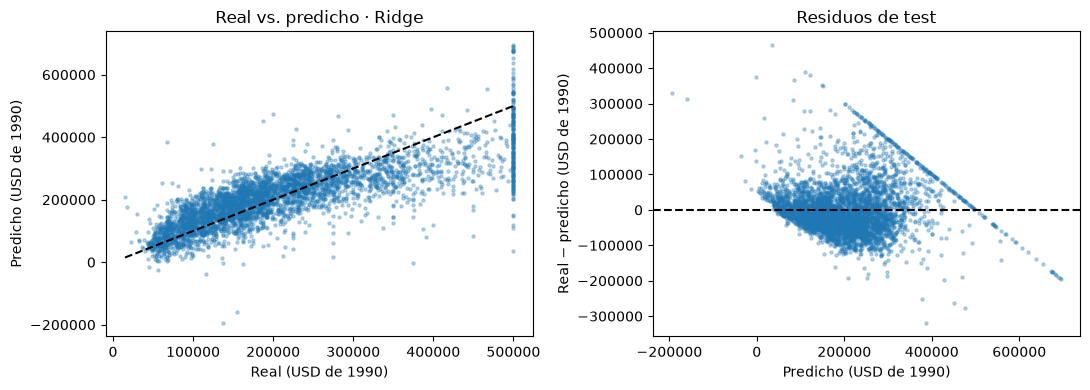

In [ ]:
# Ajustar la mejor configuración de cada modelo y calcular sus métricas.
modelos_h, filas_h = {}, []

for nombre, fila in cv_h.iterrows():
    modelo = (
        clone(busqueda_h.estimator)
        .set_params(**fila.parametros)
        .fit(Xh_train, yh_train)
    )
    modelos_h[nombre] = modelo
    pred = modelo.predict(Xh_test)
    filas_h.append(
        [
            nombre,
            root_mean_squared_error(yh_train, modelo.predict(Xh_train)),
            root_mean_squared_error(yh_test, pred),
            mean_absolute_error(yh_test, pred),
            r2_score(yh_test, pred),
        ]
    )

# Comparar los errores de entrenamiento y test en una tabla.
test_h = pd.DataFrame(
    filas_h,
    columns=['modelo', 'RMSE_train', 'RMSE_test', 'MAE_test', 'R2'],
).set_index('modelo')
display(test_h.round(3))

# Graficar los precios reales y predichos del modelo seleccionado.
pred_h = modelos_h[ganador_h].predict(Xh_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yh_test, pred_h, s=5, alpha=.3)
ax[0].plot(
    [yh_test.min(), yh_test.max()],
    [yh_test.min(), yh_test.max()],
    'k--',
)
ax[0].set(
    title=f'Real vs. predicho · {ganador_h}',
    xlabel='Real (USD de 1990)',
    ylabel='Predicho (USD de 1990)',
)

# Revisar la distribución de los residuos respecto de las predicciones.
ax[1].scatter(pred_h, yh_test - pred_h, s=5, alpha=.3)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set(
    title='Residuos de test',
    xlabel='Predicho (USD de 1990)',
    ylabel='Real − predicho (USD de 1990)',
)

fig.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
# Comparar los coeficientes usando los nombres de las variables transformadas.
coef_h = pd.DataFrame(
    {
        nombre: pd.Series(
            modelos_h[nombre]['modelo'].coef_,
            index=modelos_h[nombre]['preparar'].get_feature_names_out(),
        )
        for nombre in ['LinearRegression', 'Ridge', 'Lasso']
    }
)
display(coef_h.round(2))
print(
    'Referencia de costa:',
    modelos_h['LinearRegression']['preparar']
    .named_transformers_['cat'][-1].categories_[0][0],
)

# Calcular la reducción del RMSE frente al modelo que predice la media.
mejora_h = 100 * (
    1
    - test_h.loc[ganador_h, 'RMSE_test']
    / test_h.loc['DummyRegressor', 'RMSE_test']
)

# Mostrar la mejora y el coeficiente del ingreso en la regresión lineal.
display(
    Markdown(
        f"**{ganador_h}** reduce el RMSE de la media en **{mejora_h:.1f}%**. "
        f"Coeficiente de ingreso en la lineal: **USD {coef_h.loc['num__median_income', 'LinearRegression']:,.0f}**."
    )
)


,LinearRegression,Ridge,Lasso
num__longitude,-53826.65,-53779.27,-53661.29
num__latitude,-54415.70,-54373.36,-54281.06
num__housing_median_age,13889.87,13895.48,13885.61
num__total_rooms,-13094.25,-13055.02,-12881.02
num__total_bedrooms,43068.18,43042.52,42937.76
num__population,-43403.43,-43395.36,-43337.87
num__households,18382.20,18361.21,18238.22
num__median_income,75167.77,75152.53,75110.28
cat__ocean_proximity_INLAND,-39786.66,-39819.99,-39871.96
cat__ocean_proximity_ISLAND,136125.07,108893.02,94865.57


Referencia de costa: <1H OCEAN


**Ridge** reduce el RMSE de la media en **38.8%**. Coeficiente de ingreso en la lineal: **USD 75,168**.

### ¿Qué significan estos resultados para Housing?

**El modelo aprende una relación útil, pero todavía comete errores importantes.**
La regresión lineal obtiene un RMSE de **USD 70.059**. Ridge, elegido por validación
cruzada, obtiene **USD 70.067**, frente a **USD 114.486** del baseline que siempre
predice la media: una reducción del **38,8 %**. Todos estos valores son USD de 1990
y corresponden al valor mediano de una zona censal, no al precio de una casa individual.

Para entender el error cotidiano, el MAE de Ridge es más directo: las predicciones
se apartan del valor real en unos **USD 50.678 en promedio absoluto**. El RMSE es
mayor porque da más peso a los errores grandes; no significa que cada predicción
se equivoque en USD 70.067. El **R² de 0,625** indica que el modelo explica cerca del
62,5 % de la variación del objetivo en test; no equivale a un 62,5 % de accuracy.

El RMSE de Ridge pasa de **USD 68.435 en train a USD 70.067 en test**. La brecha es
pequeña en esta partición y no muestra una señal fuerte de sobreajuste. Aun así,
no demuestra que el modelo funcione igual en otras épocas o regiones. Ridge y
Lasso quedan prácticamente empatados con la lineal: la regularización no aporta
una mejora relevante aquí. Mantenemos Ridge porque fue seleccionado con CV en
train, aunque la lineal tenga un RMSE de test ligeramente menor.

**¿Qué nos dicen los coeficientes?** En la regresión lineal, una desviación estándar
más de `median_income` se asocia con unos **USD 75.168 más** en el valor predicho,
manteniendo los demás predictores constantes. No es el efecto de aumentar un dólar
el ingreso. La categoría `INLAND` se asocia con unos **USD 39.787 menos** respecto
a `<1H OCEAN`. Son asociaciones del modelo, no pruebas de causalidad; además, los
predictores relacionados entre sí pueden dificultar la interpretación individual.

El modelo sirve como referencia inicial para estas zonas, pero su error no permite
tratar cada predicción como una tasación precisa. El tope de **USD 500.001** también
limita lo que podemos aprender sobre las zonas más caras.


## 3. Conclusiones y límites

Los modelos superan claramente a predecir siempre la media, pero mantienen un
error absoluto medio cercano a **USD 50.700**. Ridge y Lasso no muestran una ventaja
relevante sobre la regresión lineal con estas variables y parámetros.

La selección de modelos y parámetros usa CV en train; después de observar test
no reajustamos los modelos. Los mejores puntajes de CV pueden ser optimistas por
la búsqueda de parámetros. Las cifras comentadas corresponden a la ejecución
original, con semilla 42 y los CSV locales.

- Conservamos los precios topados y no conocemos su valor sin ese límite.
  La división aleatoria entre zonas no prueba generalización espacial o temporal.
- **Siguiente paso:** probar variables derivadas y validación por zonas. Si las
  decisiones se toman después de este análisis, hará falta un nuevo conjunto
  independiente para evaluar la versión final sin reutilizar este test como
  criterio de selección.
